# Topography Lai Hoa: cross-shore profile and erosional cliffs

This notebook makes the topography figures and tables from the RTK-GPS points measured at Lai Hoa.

**Input:** `data/laihoa.csv` (id, northing, easting, elevation, code), in VN-2000.
These data were collected during fieldwork together with ICOE and are **not included** in this repository.

**Output:** figures in `results/figures/`, tables in `results/tables/`.

## 1. Settings

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

By default (`SAVE = False`), the notebook only shows the figures and tables, so the files in `results/` (the versions used in the report) are not changed.
Set `SAVE = True` to save them in `results/` again -> this overwrites the files there.

In [2]:
SAVE = False   # True = save the figures and tables in results/ (overwrites the files there)

path = '../data/laihoa.csv'
fig_dir = '../results/figures'
table_dir = '../results/tables'

if SAVE:
    for folder in (fig_dir, table_dir):
        os.makedirs(folder, exist_ok=True)

- `vertical_offset`: measured RTK height minus the known height (4.00 m, Hon Dau) of the Chien Tup sluice gate.
- `outliers`: points that are not used (pole sunk into the mud, or measured outside the profile).
- The points are projected onto a shore-normal axis (`cross_shore_bearing`), with the dike crest (`origin_id`) as zero.
- A line with one bend is used where it fits significantly better than a straight line (F-test, p < `max_p`).

In [3]:
vertical_offset = 1.97893
outliers = [234, 238, 328, 186, 198, 199, 200, 201, 202, 203]

cross_shore_bearing = 160
origin_id = 364
parts = ['healthy', 'unhealthy', 'offshore']
colors = {'healthy': 'green', 'unhealthy': 'gray', 'offshore': 'blue'}
max_p = 0.001

# Cliffs: point ids from the top to the foot, the top and foot point of the cliff face,
# and the order in which the points were measured (for the arrows in the map)
cliff_ranges = {
    'SE cliff': [(165, 175)],
    'SW cliff': [(176, 185)],
    'N cliff':  [(197, 194), (187, 193)],
}
cliff_faces = {'SW cliff': (179, 181), 'N cliff': (197, 189)}
measured_order = {'SE cliff': [(165, 175)], 'SW cliff': [(176, 185)], 'N cliff': [(187, 193), (194, 197)]}
cliff_colors = {'SE cliff': 'orange', 'SW cliff': 'red', 'N cliff': 'purple'}

## 2. Data

Base-station records (`RTCM...`) are removed. The zone of each point (`piece`) is the code without its number.

In [4]:
df = pd.read_csv(path, header=None, names=['id', 'northing', 'easting', 'z', 'code'])
df = df[~df['id'].str.startswith('RTCM')].copy()
df['z'] = df['z'] - vertical_offset
df['id'] = df['id'].astype(int)
df['piece'] = df['code'].str.extract(r'^([a-z]+)', expand=False)

origin = df[df['id'] == origin_id].iloc[0]
angle = np.radians(cross_shore_bearing)
df['cross_shore_distance'] = (df['easting'] - origin['easting']) * np.sin(angle) + (df['northing'] - origin['northing']) * np.cos(angle)

df_keep = df[~df['id'].isin(outliers)].copy()
df_discard = df[df['id'].isin(outliers)].copy()

df_keep['piece'].value_counts(sort=False)

piece
cliff         32
unhealthy     33
offshore      47
healthy       71
breakwater     3
slope          4
Name: count, dtype: int64

## 3. Slopes of the cross-shore profile

`fit` fits a straight line (least squares), or a line with one bend at `bend`. It returns the coefficients,
their covariance, the sum of squared errors and the fitted line. `find_bend` tries every point as the bend
(except the first and last 5) and keeps the best one.

In [5]:
def fit(x, z, bend=None):
    if bend is None:
        X = np.column_stack([np.ones_like(x), x])
    else:
        X = np.column_stack([np.ones_like(x), x, np.maximum(x - bend, 0)])
    coef = np.linalg.lstsq(X, z, rcond=None)[0]
    z_line = X @ coef
    error = ((z_line - z) ** 2).sum()
    cov = error / (len(x) - X.shape[1]) * np.linalg.inv(X.T @ X)
    return coef, cov, error, z_line


def find_bend(x, z, min_points=5):
    candidates = x[min_points:-min_points]
    errors = [fit(x, z, bend)[2] for bend in candidates]
    return candidates[np.argmin(errors)]


def as_one_in(slope):
    x = 1 / abs(slope)
    return f'1:{float(f"{x:.2g}"):g}'


def profile(part):
    points = df_keep[df_keep['piece'] == part].sort_values('cross_shore_distance')
    return points['cross_shore_distance'].to_numpy(), points['z'].to_numpy()

F-test: checks if a line with one bend fits significantly better than a straight line.

In [6]:
rows = []
use_bend = {}
for part in parts:
    x, z = profile(part)
    error_line = fit(x, z)[2]
    error_bend = fit(x, z, find_bend(x, z))[2]
    f_value = (error_line - error_bend) / (error_bend / (len(x) - 3))
    p_value = stats.f.sf(f_value, 1, len(x) - 3)
    use_bend[part] = p_value < max_p
    rows.append({'piece': part, 'points': len(x), 'F': round(f_value, 1), 'p': f'{p_value:.1e}', 'bend': use_bend[part]})

pd.DataFrame(rows)

,piece,points,F,p,bend
0,healthy,71,121.9,8.2e-17,True
1,unhealthy,33,2.8,1.1e-01,False
2,offshore,47,122.3,2.8e-14,True


Slope per zone (and per segment if there is a bend), with the 95% uncertainty. A slope smaller than its
uncertainty is marked as flat. The median elevation per zone is given as well.

In [7]:
rows = []
lines = {}
for part in parts:
    x, z = profile(part)

    if use_bend[part]:
        bend = find_bend(x, z)
        coef, cov, _, z_line = fit(x, z, bend)
        segments = [('before bend', x.min(), bend, coef[1], cov[1, 1]),
                    ('after bend', bend, x.max(), coef[1] + coef[2], cov[1, 1] + cov[2, 2] + 2 * cov[1, 2])]
    else:
        coef, cov, _, z_line = fit(x, z)
        segments = [('whole', x.min(), x.max(), coef[1], cov[1, 1])]

    lines[part] = (x, z_line)

    for segment, start, end, slope, variance in segments:
        plus_minus = 1.96 * np.sqrt(variance)
        rows.append({
            'piece': part,
            'segment': segment,
            'from (m)': round(start),
            'to (m)': round(end),
            'points': ((x >= start) & (x <= end)).sum(),
            'slope (%)': f'{slope * 100:.2f} ± {plus_minus * 100:.2f}',
            'slope (1:x)': as_one_in(slope) + (' (flat)' if abs(slope) < plus_minus else ''),
        })

table = pd.DataFrame(rows)
if SAVE:
    table.to_csv(os.path.join(table_dir, 'slopes_laihoa.csv'), index=False)
print(table.to_string(index=False))
print()
print('Median elevation (m, Hon Dau):')
print(df_keep[df_keep['piece'].isin(parts)].groupby('piece')['z'].median().loc[parts].round(2).to_string())

    piece     segment  from (m)  to (m)  points    slope (%)   slope (1:x)
  healthy before bend        14     133      54 -0.16 ± 0.05         1:640
  healthy  after bend       133     172      18 -1.25 ± 0.17          1:80
unhealthy       whole        25     186      33 -0.04 ± 0.06 1:2700 (flat)
 offshore before bend       190     210       8 -0.66 ± 0.10         1:150
 offshore  after bend       210     479      40 -0.05 ± 0.01        1:1900

Median elevation (m, Hon Dau):
piece
healthy      1.29
unhealthy    0.74
offshore    -0.57


## 4. Cliffs

Each cliff line runs from the top to the foot. The distance from the top is the walked distance between the points.
The slope of the cliff face = height / horizontal distance between the last point on top and the first point at the
foot. The real top and foot lie between the points, so this is a minimum steepness. No clear face was measured at the SE cliff.

In [8]:
cliff_points = df_keep.set_index('id')

cliff_lines = {}
for cliff, ranges in cliff_ranges.items():
    ids = []
    for first, last in ranges:
        step = 1 if last >= first else -1
        ids += list(range(first, last + step, step))
    line = cliff_points.loc[ids].copy()
    step = np.hypot(line['easting'].diff(), line['northing'].diff()).fillna(0)
    line['distance_from_top'] = step.cumsum()
    cliff_lines[cliff] = line

In [9]:
cliff_rows = []
for cliff, (top_id, foot_id) in cliff_faces.items():
    top = cliff_lines[cliff].loc[top_id]
    foot = cliff_lines[cliff].loc[foot_id]
    height = top['z'] - foot['z']
    horizontal = foot['distance_from_top'] - top['distance_from_top']
    cliff_rows.append({
        'cliff': cliff,
        'top to foot': f'{top_id} to {foot_id}',
        'height (m)': round(height, 2),
        'horizontal (m)': round(horizontal, 2),
        'slope (1:x)': as_one_in(height / horizontal),
    })

cliff_table = pd.DataFrame(cliff_rows)
if SAVE:
    cliff_table.to_csv(os.path.join(table_dir, 'cliffs_laihoa.csv'), index=False)
print(cliff_table.to_string(index=False))

   cliff top to foot  height (m)  horizontal (m) slope (1:x)
SW cliff  179 to 181        0.68            1.56       1:2.3
 N cliff  197 to 189        0.71            7.41        1:10


## 5. Figures

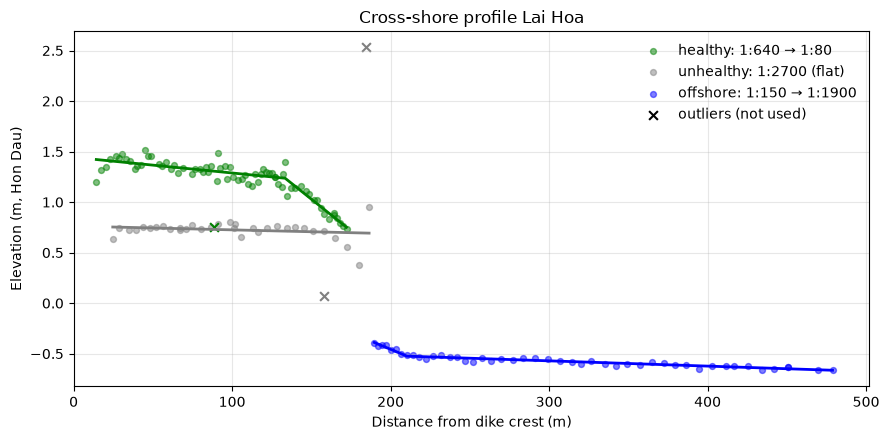

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for part in parts:
    points = df_keep[df_keep['piece'] == part]
    slopes = table.loc[table['piece'] == part, 'slope (1:x)']
    ax.scatter(points['cross_shore_distance'], points['z'], color=colors[part], alpha=0.5, s=18, label=f"{part}: {' → '.join(slopes)}")

for part, (x, z_line) in lines.items():
    ax.plot(x, z_line, color=colors[part], lw=2)

for part in parts:
    removed = df_discard[df_discard['piece'] == part]
    ax.scatter(removed['cross_shore_distance'], removed['z'], marker='x', color=colors[part], s=40)
ax.scatter([], [], marker='x', color='black', s=40, label='outliers (not used)')

ax.set_title('Cross-shore profile Lai Hoa')
ax.set_xlabel('Distance from dike crest (m)')
ax.set_ylabel('Elevation (m, Hon Dau)')
ax.set_xlim(left=0)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'cross_shore_profile_laihoa.png'), dpi=300, bbox_inches='tight')
plt.show()

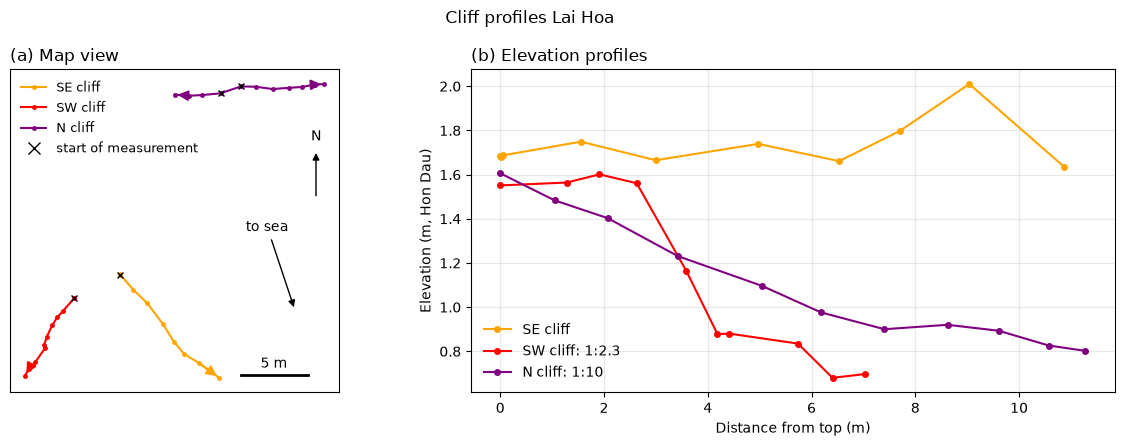

In [11]:
fig, (ax_map, ax_profile) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})

# (a) Map view in metres from the first SE cliff point, with the walking direction
ref = cliff_lines['SE cliff'].iloc[0]
for cliff, line in cliff_lines.items():
    east = line['easting'] - ref['easting']
    north = line['northing'] - ref['northing']
    ax_map.plot(east, north, '.-', color=cliff_colors[cliff], ms=5, label=cliff)
    for start, end in measured_order[cliff]:
        ax_map.plot(east[start], north[start], 'x', ms=5, color='black', mew=1, zorder=3)
        ax_map.annotate('', xy=(east[end], north[end]), xytext=(east[end - 1], north[end - 1]),
                        arrowprops=dict(arrowstyle='-|>', color=cliff_colors[cliff], lw=1.5, mutation_scale=15))

ax_map.plot([], [], 'x', ms=8, color='black', mew=1, label='start of measurement')
sea = np.radians(cross_shore_bearing)
ax_map.annotate('to sea', xy=(11 + 6 * np.sin(sea), 3 + 6 * np.cos(sea)), xytext=(11, 3),
                arrowprops=dict(arrowstyle='-|>', color='black'), ha='center', va='bottom')
ax_map.annotate('', xy=(0.93, 0.75), xytext=(0.93, 0.6), xycoords='axes fraction',
                arrowprops=dict(arrowstyle='-|>', color='black'))
ax_map.text(0.93, 0.77, 'N', transform=ax_map.transAxes, ha='center', va='bottom')
ax_map.plot([9, 14], [-7.5, -7.5], color='black', lw=2)
ax_map.text(11.5, -7.2, '5 m', ha='center', va='bottom')
ax_map.set_aspect('equal')
ax_map.set_xticks([])
ax_map.set_yticks([])
ax_map.set_title('(a) Map view', loc='left')
ax_map.legend(frameon=False, loc='upper left', fontsize=9)

# (b) Elevation along each cliff line
for cliff, line in cliff_lines.items():
    label = cliff
    if cliff in cliff_faces:
        label = f"{cliff}: {cliff_table.loc[cliff_table['cliff'] == cliff, 'slope (1:x)'].iloc[0]}"
    ax_profile.plot(line['distance_from_top'], line['z'], 'o-', color=cliff_colors[cliff], ms=4, label=label)

ax_profile.set_xlabel('Distance from top (m)')
ax_profile.set_ylabel('Elevation (m, Hon Dau)')
ax_profile.set_title('(b) Elevation profiles', loc='left')
ax_profile.grid(alpha=0.3)
ax_profile.legend(frameon=False)

fig.suptitle('Cliff profiles Lai Hoa')
plt.tight_layout()
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'cliff_profiles_laihoa.png'), dpi=300, bbox_inches='tight')
plt.show()